# EDA: статьи arXiv cs.LG и cs.AI

Ноутбук к ДЗ 2. Цель – проверить на реальных данных предпосылки из дизайн-документа
(`docs/ml_system_design_doc.md`, разделы 1.2 и 2.1): сколько статей приходит в день, какого
качества метаданные, доступен ли полный текст и сколько он стоит в токенах, насколько отбор
по эмбеддингам лучше фильтра по ключевым словам на gold-наборе.

**Данные** собирает `scripts/collect_arxiv.py` (сырые выгрузки в `data/raw/` не коммитятся,
производные таблицы лежат в `data/processed/` и `data/gold/`):

| Набор | Откуда | Объем |
|---|---|---|
| Метаданные | arXiv API, `cat:cs.LG OR cat:cs.AI`, по дням подачи | 17.09–28.10.2026, 6 недель |
| Месячные объемы | arXiv API, только `totalResults` | 2018-01 – 2026-09 |
| Полные тексты | arxiv.org: HTML, e-print (LaTeX), PDF | случайные 100 статей |
| Gold-набор | разметка автора в `scripts/label_gold.py` | 200 статей за 26–27.10 |

Воспроизведение: `uv sync --group eda`, затем подкоманды `meta`, `monthly`, `fulltext` скрипта
сбора и `uv run jupyter nbconvert --to notebook --execute --inplace notebooks/01_eda_arxiv.ipynb`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, PROCESSED, GOLD = ROOT / "data" / "raw", ROOT / "data" / "processed", ROOT / "data" / "gold"
FIRST_DAY, LAST_DAY = "2026-09-17", "2026-10-28"
CATEGORIES = ("cs.LG", "cs.AI")
FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)


def show(fig: plt.Figure, name: str) -> None:
    fig.savefig(FIGURES / f"{name}.png", dpi=120, bbox_inches="tight")
    plt.show()


BLUE, ORANGE, AQUA, GRAY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#b4b3ad", "#52514e"
plt.rcParams.update(
    {
        "figure.dpi": 80,
        "figure.figsize": (9, 3.4),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": GRAY,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": "#e6e5e0",
        "grid.linewidth": 0.8,
        "axes.titlelocation": "left",
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "text.color": INK,
        "axes.labelcolor": INK,
        "xtick.color": INK,
        "ytick.color": INK,
        "font.size": 10,
        "legend.frameon": False,
    }
)
pd.set_option("display.precision", 2)

## 1. Состав и объем данных

Каждая строка – статья, которая попала в `cs.LG` или `cs.AI` как основная категория или как
cross-list. Дата – день подачи первой версии (UTC), а не день анонса: API не отдает дату
анонса. Данные – снимок arXiv API на 01.11.2026. Свежие статьи появляются в API примерно через
3 дня после анонса, поэтому на момент сбора полными были дни по 28.10. Окно
17.09–28.10 зафиксировано (`FIRST_DAY`, `LAST_DAY`), чтобы цифры воспроизводились при
повторном сборе.

In [2]:
meta = pd.read_parquet(RAW / "arxiv_meta.parquet")
meta["ts"] = pd.to_datetime(meta["published"])
meta["day"] = meta["ts"].dt.tz_localize(None).dt.normalize()
meta = meta[(meta["day"] >= FIRST_DAY) & (meta["day"] <= LAST_DAY)].reset_index(drop=True)
cats = meta["categories"].apply(set)
meta["in_lg"] = cats.apply(lambda c: "cs.LG" in c)
meta["in_ai"] = cats.apply(lambda c: "cs.AI" in c)
meta["is_primary"] = meta["primary_category"].isin(CATEGORIES)
print(f"Статей: {len(meta)}, уникальных id: {meta['id'].nunique()}, дней: {meta['day'].nunique()}")
meta[["id", "version", "primary_category", "categories", "published", "title"]].head(3)

Статей: 16030, уникальных id: 16030, дней: 42


,id,version,primary_category,categories,published,title
0,2609.19512,1,cs.RO,"[cs.RO, cs.AI]",2026-09-17T00:01:06Z,CoreSense: Traceable Failure Recall and Confli...
1,2609.19513,2,cs.AI,"[cs.AI, cs.LG]",2026-09-17T00:04:09Z,"QVAC Genesis III: A Large-Scale, High-Quality ..."
2,2609.19515,1,cs.AI,"[cs.AI, cs.LG]",2026-09-17T00:05:25Z,LLM-as-an-Improver: Turning Verification into ...


### 1.1. Сколько статей в день

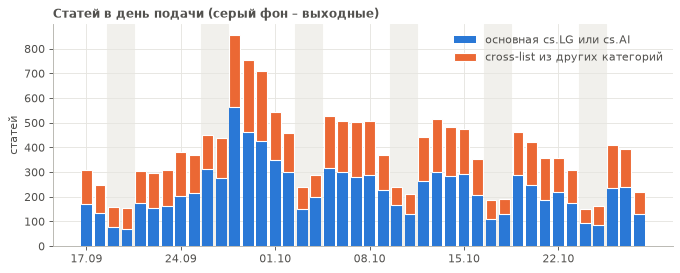

,mean,min,max
Пн,501.0,305,856
Вт,481.0,295,754
Ср,431.0,220,708
Чт,429.0,307,544
Пт,352.0,248,457
Сб,238.0,152,449
Вс,241.0,153,437


In [3]:
daily = meta.groupby(["day", "is_primary"]).size().unstack(fill_value=0)
daily.columns = ["cross-list из других категорий", "основная cs.LG или cs.AI"]
days = pd.DatetimeIndex(daily.index)
weekend = days.day_of_week >= 5

fig, ax = plt.subplots(figsize=(10, 3.6))
x = np.arange(len(daily))
primary = daily["основная cs.LG или cs.AI"]
cross = daily["cross-list из других категорий"]
ax.bar(x, primary, color=BLUE, width=0.8, label="основная cs.LG или cs.AI")
ax.bar(
    x,
    cross,
    bottom=primary,
    color=ORANGE,
    width=0.8,
    edgecolor="white",
    linewidth=1,
    label="cross-list из других категорий",
)
ax.set_xticks(x[::7], [d.strftime("%d.%m") for d in daily.index[::7]])
for i in np.flatnonzero(weekend):
    ax.axvspan(i - 0.5, i + 0.5, color="#f1f0ec", zorder=0)
ax.set_title("Статей в день подачи (серый фон – выходные)")
ax.set_ylabel("статей")
ax.legend(loc="upper right")
show(fig, "01_daily_volume")

by_dow = daily.sum(axis=1).groupby(days.day_of_week).agg(["mean", "min", "max"]).round()
by_dow.index = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
by_dow

Дайджест приходит после анонса arXiv, а не по дням подачи. Анонс выходит по будням
(вс–чт вечером по Восточному времени), в него попадает все, что подали до 14:00 ET
предыдущего рабочего дня, поэтому в понедельничный анонс входят пятница и выходные.
Ниже – приближенная разбивка по пакетам анонса (без учета праздников и замен версий):
это и есть размер ежедневного пула кандидатов для отбора.

In [4]:
shifted = meta["ts"].dt.tz_convert("America/New_York").dt.tz_localize(None) - pd.Timedelta(hours=14)
batch = shifted.dt.normalize() + pd.Timedelta(days=1)
batch = batch.where(
    batch.dt.day_of_week < 5, batch + pd.to_timedelta(7 - batch.dt.day_of_week, "D")
)
meta["batch"] = batch
pool = meta.groupby("batch").agg(all=("id", "size"), primary=("is_primary", "sum"))
pool = pool.iloc[1:-1]
pool["dow"] = pd.DatetimeIndex(pool.index).day_of_week
summary = pool.groupby("dow")[["all", "primary"]].median().round()
summary.index = ["Пн", "Вт", "Ср", "Чт", "Пт"][: len(summary)]
print(
    f"Пакетов: {len(pool)}; медиана пула: {pool['all'].median():.0f} статей, "
    f"с основной категорией cs.LG/cs.AI: {pool['primary'].median():.0f}; "
    f"5 карточек – это {5 / pool['all'].median():.1%} пула"
)
summary

Пакетов: 29; медиана пула: 486 статей, с основной категорией cs.LG/cs.AI: 297; 5 карточек – это 1.0% пула


,all,primary
Пн,844.0,530.0
Вт,473.0,268.0
Ср,432.0,251.0
Чт,496.0,297.0
Пт,348.0,207.0


**Вывод.**
- За 6 недель (17.09–28.10.2026) в cs.LG ∪ cs.AI пришло 16 030 статей. По будням подают
  350–500 статей в день, по выходным ~240.
- Ежедневный пул кандидатов (пакет анонса) – медиана ~490 статей, из них ~300 с основной
  категорией cs.LG или cs.AI. Понедельничный пакет включает пятницу и выходные и вдвое больше
  (~840). 5 карточек – около 1% пула, поэтому ошибка отбора обходится дорого: из сотни
  кандидатов, похожих на интересы, в дайджест попадает пять.
- Объем неровный: 28–30.09 был всплеск до 856 статей в день (вероятно, дедлайн крупной
  конференции). Отбор и бюджет должны выдерживать пул до ~1 000 статей в день, а правило
  «top-5 выше порога» с абсолютным порогом в такие дни даст больше кандидатов выше порога –
  это нормально, мы все равно берем пять.
- Следствие для расписания: дайджест строим по пакетам анонса (5 дней в неделю), а не по дням
  подачи; в продакшене данные берем из ежедневного анонса (OAI-PMH или RSS), потому что
  search API отстает от анонса на ~3 дня.

### 1.2. Состав: основные категории и пересечение cs.LG и cs.AI

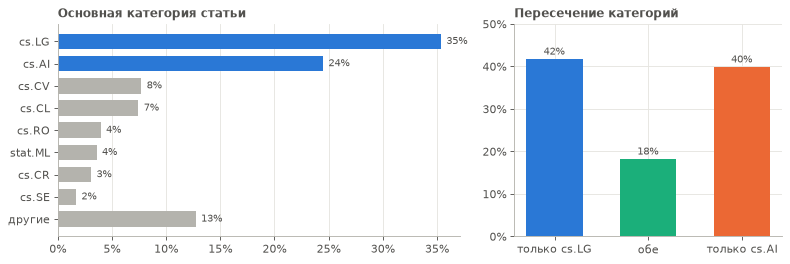

Число категорий у статьи: {'mean': 2.030255770430443, '50%': 2.0, 'max': 6.0}


In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={"width_ratios": [3, 2]})
top = meta["primary_category"].value_counts()
top = pd.concat([top.head(8), pd.Series({"другие": top.iloc[8:].sum()})])
share = top / len(meta)
colors = [BLUE if c in CATEGORIES else GRAY for c in share.index]
ax1.barh(share.index[::-1], share.values[::-1], color=colors[::-1], height=0.7)
for y, v in enumerate(share.values[::-1]):
    ax1.text(v + 0.005, y, f"{v:.0%}", va="center", fontsize=9)
ax1.set_title("Основная категория статьи")
ax1.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax1.grid(axis="y", visible=False)

overlap = pd.Series(
    {
        "только cs.LG": (meta["in_lg"] & ~meta["in_ai"]).mean(),
        "обе": (meta["in_lg"] & meta["in_ai"]).mean(),
        "только cs.AI": (~meta["in_lg"] & meta["in_ai"]).mean(),
    }
)
ax2.bar(overlap.index, overlap.values, color=[BLUE, AQUA, ORANGE], width=0.6)
for i, v in enumerate(overlap.values):
    ax2.text(i, v + 0.01, f"{v:.0%}", ha="center", fontsize=9)
ax2.set_ylim(0, 0.5)
ax2.set_title("Пересечение категорий")
ax2.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.tight_layout()
show(fig, "02_categories")
print(
    "Число категорий у статьи:",
    meta["categories"].apply(len).describe()[["mean", "50%", "max"]].to_dict(),
)

**Вывод.**
- 41% статей в пуле – cross-list из других категорий: компьютерное зрение (cs.CV, 8%),
  NLP (cs.CL, 7%), робототехника (cs.RO, 4%), stat.ML (4%), безопасность (cs.CR, 3%).
  Это основной источник шума для пользователя, который выбрал cs.LG и cs.AI, но и источник
  релевантных статей (например, LLM-работы часто с основной cs.CL).
- cs.LG и cs.AI пересекаются слабо: только 18% статей стоят в обеих категориях. Выбор двух
  категорий почти удваивает пул, а не дублирует его.
- Ограничение gold-набора: случайная выборка собрана только из статей с основной категорией
  cs.LG/cs.AI, то есть не покрывает 41% cross-list. Пулинг в разделе 4 идет по всему пулу и
  показывает, что для профиля про рекомендации и поиск половина релевантных статей – cross-list
  (в основном cs.IR). Для пилотных разметчиков выборку берем из всего пула.

### 1.3. Тренд по месяцам, 2018–2026

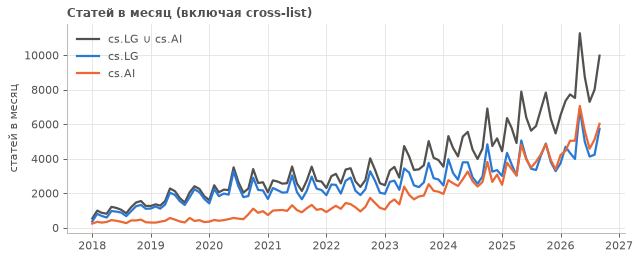

,cs_lg,cs_ai,union,"рост union, раз к 2018"
month,,,,
2018,875.0,357.0,1073.0,1.0
2019,1608.0,397.0,1794.0,1.7
2020,2158.0,618.0,2463.0,2.3
2021,2211.0,1044.0,2710.0,2.5
2022,2394.0,1234.0,2961.0,2.8
2023,2752.0,1822.0,3700.0,3.4
2024,3316.0,2754.0,4861.0,4.5
2025,3835.0,3764.0,6147.0,5.7
2026,4742.0,5235.0,8265.0,7.7


In [6]:
monthly = pd.read_csv(PROCESSED / "monthly_counts.csv", parse_dates=["month"])
monthly = monthly[monthly["month"] < LAST_DAY[:7]]  # октябрь в API еще не полный
fig, ax = plt.subplots()
for col, color, label in (
    ("union", INK, "cs.LG ∪ cs.AI"),
    ("cs_lg", BLUE, "cs.LG"),
    ("cs_ai", ORANGE, "cs.AI"),
):
    ax.plot(monthly["month"], monthly[col], color=color, linewidth=2, label=label)
ax.set_title("Статей в месяц (включая cross-list)")
ax.set_ylabel("статей в месяц")
ax.legend(loc="upper left")
show(fig, "03_monthly_trend")

yearly = monthly.groupby(monthly["month"].dt.year)[["cs_lg", "cs_ai", "union"]].mean().round()
yearly["рост union, раз к 2018"] = (yearly["union"] / yearly["union"].iloc[0]).round(1)
yearly

**Вывод.**
- Поток растет быстро: в среднем за месяц в cs.LG ∪ cs.AI в 2026 году 8,3 тыс. статей против
  1,1 тыс. в 2018-м (в 7,7 раза) и 6,1 тыс. в 2025-м (+35% за год). Ручной просмотр
  становится все дороже – это аргумент в пользу продукта из 1.1.
- cs.AI растет быстрее cs.LG и в 2026 году его обогнал (5,2 тыс. против 4,7 тыс. в месяц):
  поток LLM-статей уходит в cs.AI.
- Есть сезонность: каждый май – пик (дедлайн NeurIPS), в 2026 году 11,3 тыс. за месяц, в
  сентябре – второй пик. В пиковые недели пул в 1,5–2 раза больше обычного.
- Следствия: бюджет и время отбора закладываем с запасом ×2 к медианному дню и пересматриваем
  раз в полгода; при текущем росте через год пул будет ~650 статей в обычный день.

## 2. Качество метаданных

Отбор в MVP работает по заголовку и аннотации, поэтому проверяем именно их: пропуски,
длину, LaTeX-разметку, язык, дубликаты и версии.

In [7]:
quality = pd.Series(
    {
        "пустой заголовок": (meta["title"].str.len() == 0).mean(),
        "аннотация короче 30 слов": (meta["abstract"].str.split().str.len() < 30).mean(),
        "нет comment": meta["comment"].isna().mean(),
        "нет journal_ref": meta["journal_ref"].isna().mean(),
        "нет DOI": meta["doi"].isna().mean(),
        "в выгрузке версия > 1": (meta["version"] > 1).mean(),
        "есть $…$ в аннотации": meta["abstract"].str.contains("$", regex=False).mean(),
        "есть LaTeX-команды (\\cmd)": meta["abstract"].str.contains(r"\\[A-Za-z]+").mean(),
        "есть LaTeX в заголовке": meta["title"].str.contains(r"\$|\\[A-Za-z]+").mean(),
        "> 5% не-ASCII символов в аннотации": meta["abstract"]
        .apply(lambda s: sum(ord(ch) > 127 for ch in s) / max(len(s), 1) > 0.05)
        .mean(),
        "ссылка на GitHub в аннотации": meta["abstract"].str.contains("github.com").mean(),
        "withdrawn в comment": meta["comment"]
        .fillna("")
        .str.contains("withdrawn", case=False)
        .mean(),
    }
)
print(
    f"Дубликатов id: {meta['id'].duplicated().sum()}, "
    f"дубликатов заголовков: {meta['title'].str.lower().duplicated().sum()}"
)
quality.to_frame("доля статей").style.format("{:.1%}")

Дубликатов id: 0, дубликатов заголовков: 0


,доля статей
пустой заголовок,0.0%
аннотация короче 30 слов,0.0%
нет comment,51.2%
нет journal_ref,97.8%
нет DOI,98.0%
в выгрузке версия > 1,11.8%
есть $…$ в аннотации,18.4%
есть LaTeX-команды (\cmd),14.9%
есть LaTeX в заголовке,0.7%
> 5% не-ASCII символов в аннотации,0.0%


N:\_Sole proprietor company\Образование\Магистратура\3sem\mlsd\project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


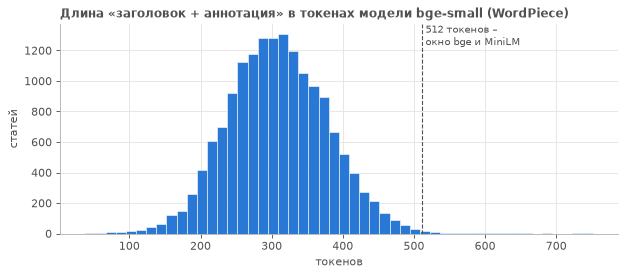

Длиннее 512 токенов (обрежутся при эмбеддинге): 0.23%


,count,mean,std,min,5%,50%,95%,max
abstract_words,16030.0,197.0,44.0,17.0,127.0,196.0,269.0,371.0
text_tokens,16030.0,309.0,70.0,38.0,199.0,306.0,425.0,751.0


In [8]:
import copy

from fastembed import TextEmbedding

# Считаем токены тем же токенизатором, что у модели эмбеддингов, без обрезки и паддинга.
tokenizer = copy.deepcopy(TextEmbedding("BAAI/bge-small-en-v1.5").model.tokenizer)
tokenizer.no_truncation()
tokenizer.no_padding()
meta["abstract_words"] = meta["abstract"].str.split().str.len()
texts = (meta["title"] + ". " + meta["abstract"]).tolist()
meta["text_tokens"] = [len(e.ids) for e in tokenizer.encode_batch(texts)]
fig, ax = plt.subplots()
ax.hist(meta["text_tokens"], bins=50, color=BLUE, edgecolor="white", linewidth=0.5)
ax.axvline(512, color=INK, linestyle="--", linewidth=1)
ax.text(512, ax.get_ylim()[1] * 0.9, " 512 токенов –\n окно bge и MiniLM", fontsize=9)
ax.set_title("Длина «заголовок + аннотация» в токенах модели bge-small (WordPiece)")
ax.set_xlabel("токенов")
ax.set_ylabel("статей")
show(fig, "04_abstract_length")
print(f"Длиннее 512 токенов (обрежутся при эмбеддинге): {(meta['text_tokens'] > 512).mean():.2%}")
meta[["abstract_words", "text_tokens"]].describe(percentiles=[0.05, 0.5, 0.95]).round().T

In [9]:
authors = meta["authors"].apply(len)
print("Авторов на статью:", authors.describe(percentiles=[0.5, 0.95]).round().to_dict())
venue = (
    meta["comment"]
    .fillna("")
    .str.contains(r"accepted|NeurIPS|ICLR|ICML|AAAI|ACL|EMNLP|CVPR|KDD", case=False)
)
print(f"Упоминание конференции или accepted в comment: {venue.mean():.1%}")
meta.loc[meta["abstract"].str.contains("$", regex=False), "abstract"].head(2).str[:300].tolist()

Авторов на статью: {'count': 16030.0, 'mean': 5.0, 'std': 7.0, 'min': 1.0, '50%': 4.0, '95%': 11.0, 'max': 559.0}
Упоминание конференции или accepted в comment: 13.3%


['Suppose we observe the first $n$ points of a sequence of random variables having length $n+1$, and wish to estimate a functional of the unobserved final point and the empirical measure of the $n$ observed training points. Such next-token functionals include the probability that the next token is nov',
 'Artificial intelligence for plant disease analysis has advanced from task-specific classifiers to multi-modal models capable of jointly interpreting visual and textual information. However, practical deployment in precision agriculture remains limited because most existing approaches treat disease u']

**Вывод.**
- Заголовки и аннотации есть у всех статей, дубликатов id и заголовков нет, мусорной кодировки
  нет. Для отбора по «заголовок + аннотация» данные чистые.
- 12% статей к моменту выгрузки уже обновились до v2+. Дедупликация – по id без версии:
  обновленную статью повторно в дайджест не отправляем.
- LaTeX в аннотациях: `$…$` у 18%, команды вида `\cmd` у 15%. Для эмбеддингов это небольшой
  шум, для карточки в Telegram – проблема отображения: формулы надо либо упрощать до
  Unicode, либо показывать как есть в моноширинном шрифте.
- `journal_ref` и DOI пусты у 98%, `comment` – у 51%. Признаки «принято на конференцию»
  (13% упоминают площадку в comment) слишком редкие и неструктурированные, чтобы на них
  опираться в первой итерации.
- Длина «заголовок + аннотация» в токенах модели bge-small – медиана ~306, 95-й перцентиль
  ~425. Окно 512 токенов превышают 0,2% статей, у них обрежется хвост аннотации: для отбора
  по эмбеддингам аннотации хватает, чанкование не нужно.

## 3. Полные тексты: доступность и длина

Пересказ в MVP строится по полному тексту, а вторая проверка сверяет утверждения с фрагментами
текста. Проверяем на случайной выборке из 100 статей (основная категория cs.LG или cs.AI):
есть ли HTML-версия (LaTeXML), LaTeX-исходник или только PDF, сколько в тексте токенов и
насколько это совпадает с оценкой 15–30 тыс. токенов из раздела 1.2.

In [10]:
ft = pd.read_csv(PROCESSED / "fulltext_sample.csv", dtype={"id": str})
has_html = ft["html_tokens"].notna()
has_tex = ft["source_kind"] == "tex"
has_pdf = ft["pdf_status"] == 200
html_ok = has_html & (ft["html_ltx_errors"] <= 5)

sources = pd.Series(
    {
        "HTML (LaTeXML)": has_html.sum(),
        "LaTeX-исходник": has_tex.sum(),
        "PDF": has_pdf.sum(),
    }
)
cascade = (
    pd.Series(np.select([html_ok, has_tex, has_pdf], ["HTML", "LaTeX", "PDF"], "нет текста"))
    .value_counts()
    .reindex(["HTML", "LaTeX", "PDF", "нет текста"], fill_value=0)
)
problems = pd.Series(
    {
        "HTML с ошибками LaTeXML": (ft["html_ltx_errors"] > 0).sum(),
        "HTML с > 5 ошибками LaTeXML": (ft["html_ltx_errors"] > 5).sum(),
        "нет ни HTML, ни LaTeX (только PDF)": (~has_html & ~has_tex).sum(),
        "PDF с глифами (cid:N) – битая кодировка": (ft["pdf_cid_glyphs"] > 0).sum(),
    }
)
print(f"Выборка: {len(ft)} статей, поэтому число статей совпадает с процентом.")
display(sources.to_frame("есть источник, статей"))
display(cascade.to_frame("текст берем из, статей (сумма = 100)"))
display(problems.to_frame("проблема, статей"))

Выборка: 100 статей, поэтому число статей совпадает с процентом.


,"есть источник, статей"
HTML (LaTeXML),94
LaTeX-исходник,97
PDF,100


,"текст берем из, статей (сумма = 100)"
HTML,92
LaTeX,5
PDF,3
нет текста,0


,"проблема, статей"
HTML с ошибками LaTeXML,6
HTML с > 5 ошибками LaTeXML,2
"нет ни HTML, ни LaTeX (только PDF)",3
PDF с глифами (cid:N) – битая кодировка,0


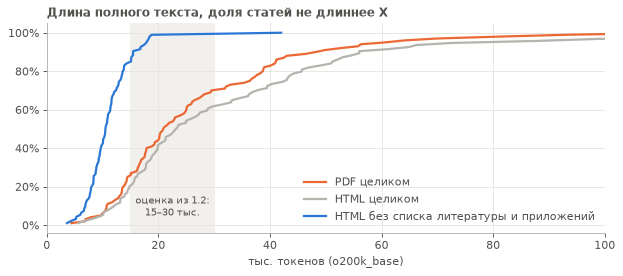

,count,mean,std,min,10%,50%,90%,max
pdf_pages,100.0,29.0,18.0,4.0,12.0,25.0,49.0,105.0
pdf_tokens,100.0,27189.0,18523.0,4415.0,10888.0,20968.0,48365.0,114878.0
html_tokens,94.0,33745.0,30820.0,5652.0,12585.0,23310.0,56005.0,212639.0
html_body_tokens,94.0,11227.0,4629.0,3634.0,6948.0,10538.0,15463.0,41999.0


In [11]:
fig, ax = plt.subplots()
series = (
    ("pdf_tokens", ORANGE, "PDF целиком"),
    ("html_tokens", GRAY, "HTML целиком"),
    ("html_body_tokens", BLUE, "HTML без списка литературы и приложений"),
)
for col, color, label in series:
    values = np.sort(ft[col].dropna().to_numpy())
    ax.plot(
        values / 1000,
        np.arange(1, len(values) + 1) / len(values),
        color=color,
        linewidth=2,
        label=label,
    )
ax.axvspan(15, 30, color="#f1f0ec", zorder=0)
ax.text(22.5, 0.05, "оценка из 1.2:\n15–30 тыс.", ha="center", fontsize=9)
ax.set_xlim(0, 100)
ax.set_title("Длина полного текста, доля статей не длиннее X")
ax.set_xlabel("тыс. токенов (o200k_base)")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.legend(loc="lower right")
show(fig, "05_fulltext_length")
ft[["pdf_pages", "pdf_tokens", "html_tokens", "html_body_tokens"]].describe(
    percentiles=[0.1, 0.5, 0.9]
).round().T

Пересчет стоимости по реальным длинам. Предпосылки: в пересказ идет основной текст (HTML
без литературы и приложений, если HTML нет – PDF), обрезанный до 30 тыс. токенов; проверка
утверждений по фрагментам – не больше объема текста и не больше 15 тыс.; вторая проверка
русского текста – 2 тыс.; выход – 2 тыс. токенов. 21 день рассылки × 5 статей, без
переиспользования пересказов между пользователями (худший случай). Цены – Caps BotHub за токен,
пакет Deluxe: 1 500 ₽ за 8,5 млн Caps.

In [12]:
text = ft["html_body_tokens"].fillna(ft["pdf_tokens"]).clip(upper=30_000)
input_tokens = text + text.clip(upper=15_000) + 2_000
output_tokens = 2_000
papers_per_month = 21 * 5
rub_per_cap = 1_500 / 8_500_000
models = {
    "Qwen3.5 Flash": (0.04, 0.18),
    "Claude Haiku 5.5": (0.07, 0.34),
    "DeepSeek V4 Flash": (0.08, 0.30),
    "GPT 4.1 Mini": (0.11, 0.44),
    "Claude Sonnet 5": (1.13, 5.65),
}
rows = []
for name, (cin, cout) in models.items():
    caps = input_tokens * cin + output_tokens * cout
    rows.append(
        {
            "модель": name,
            "Caps на статью, медиана": caps.median(),
            "₽ на пользователя в месяц, медиана": caps.median() * papers_per_month * rub_per_cap,
            "₽ в месяц, 90-й перцентиль": caps.quantile(0.9) * papers_per_month * rub_per_cap,
        }
    )
print(
    f"Входных токенов на статью: медиана {input_tokens.median():,.0f}, "
    f"90-й перцентиль {input_tokens.quantile(0.9):,.0f}; "
    f"в 1.2 закладывали 25–45 тыс."
)
pd.DataFrame(rows).set_index("модель").round()

Входных токенов на статью: медиана 23,459, 90-й перцентиль 34,390; в 1.2 закладывали 25–45 тыс.


,"Caps на статью, медиана","₽ на пользователя в месяц, медиана","₽ в месяц, 90-й перцентиль"
модель,,,
Qwen3.5 Flash,1298.0,24.0,32.0
Claude Haiku 5.5,2322.0,43.0,57.0
DeepSeek V4 Flash,2477.0,46.0,62.0
GPT 4.1 Mini,3460.0,64.0,86.0
Claude Sonnet 5,37809.0,701.0,929.0


**Вывод.**
- Полный текст доступен всегда: HTML (LaTeXML) – у 94% статей, LaTeX-исходник – у 97%,
  PDF – у 100%. Только PDF – у 3%. Ошибки конвертации LaTeXML есть у 6% HTML-версий,
  серьезные (> 5 ошибок) – у 2%. Источники пересекаются: у большинства статей есть все три. Порядок извлечения в MVP –
  HTML → LaTeX → PDF, HTML с > 5 ошибками LaTeXML пропускаем. По такому каскаду текст
  берется из HTML у 92 статей из 100, из LaTeX – у 5, из PDF – у 3, без текста не остается
  ни одной.
- Длина: PDF целиком – медиана 21 тыс. токенов (90-й перцентиль 48 тыс., максимум 115 тыс.).
  Оценка 15–30 тыс. из 1.2 верна для статьи целиком. Но больше половины объема – список
  литературы и приложения: основной текст из HTML – медиана 10,5 тыс., 90-й перцентиль
  15,5 тыс.
- Если резать литературу и приложения и ограничить контекст 30 тыс. токенов, на статью
  уходит ~23 тыс. входных токенов вместе с обеими проверками (в 1.2 закладывали 25–45 тыс.).
  Расходы на основные модели – 43–46 ₽ на пользователя в месяц по медиане и до ~60 ₽ по
  90-му перцентилю, даже без переиспользования пересказов. Это втрое ниже порога 150 ₽ и
  ниже оценки 70–110 ₽ из 1.2: запас уходит на повторные генерации и на модель качеством
  выше, если дешевые не пройдут проверку.
- Риск: приложения иногда содержат ключевые результаты, а обрезка теряет их. Проверяем на
  этапе валидации пересказа (доля неподтвержденных утверждений не меняется от обрезки).

## 4. Gold-набор

200 случайных статей с основной категорией cs.LG или cs.AI за 26 и 27.10 (два будних дня,
по 100 на день), выборка зафиксирована в `data/gold/gold_sample.csv`. Метки: `1` – хотел бы
увидеть в утреннем дайджесте, `0` – нет, `-1` – не уверен.

Случайная выборка дает несмещенные оценки доли релевантных и полноты, но в проде ранжируется
весь пул дня: ~400 статей за день подачи вместе с cross-list. Поэтому, как в TREC, добавлен
пулинг: каждый метод из раздела 5 ранжирует весь пул, и все статьи из его top-10 за день,
которых нет в выборке, размечает тот же разметчик (`data/gold/pool_<annotator>.csv`).
Неразмеченные статьи пула считаются нерелевантными.

На этой итерации выборка и пулинг размечены «серебряной» разметкой: LLM (Claude) размечал по
синтетическому профилю `data/gold/profile_silver.json` (рекомендательные системы, поиск и
ранжирование, RAG). Критерий релевантности зафиксирован в профиле до разметки, скоры моделей
при разметке не показывались. Задача разметки – отладить конвейер офлайн-оценки и получить
первые ориентиры по отбору. Ручная разметка автора и пилотных пользователей делается тем же
скриптом `scripts/label_gold.py` (`gold_author.csv`, `gold_u1.csv`, …), ноутбук подхватывает
ее автоматически и считает метрики по каждому разметчику с его профилем.

In [13]:
sample = pd.read_csv(GOLD / "gold_sample.csv", dtype={"id": str})


def read_labels(pattern: str, in_sample: bool) -> pd.DataFrame:
    files = [p for p in sorted(GOLD.glob(pattern)) if p.name != "gold_sample.csv"]
    frames = [pd.read_csv(p, dtype={"id": str}) for p in files]
    return pd.concat(frames).assign(in_sample=in_sample) if frames else pd.DataFrame()


labels = pd.concat([read_labels("gold_*.csv", True), read_labels("pool_*.csv", False)])
annotators = sorted(labels["annotator"].unique()) if len(labels) else []
if not annotators:
    print("Разметки еще нет: запустите scripts/label_gold.py")
else:
    gold = sample.merge(labels[labels["in_sample"]], on="id")
    print(f"Разметчики: {annotators}")
    display(
        labels.assign(часть=labels["in_sample"].map({True: "выборка", False: "пулинг"}))
        .groupby(["annotator", "часть"])["label"]
        .agg(
            статей="size",
            релевантных=lambda s: (s == 1).sum(),
            не_уверен=lambda s: (s == -1).sum(),
        )
    )
    display(
        gold.groupby(["annotator", "day"])["label"]
        .apply(lambda s: (s == 1).mean())
        .unstack()
        .style.format("{:.0%}")
    )

Разметчики: ['silver']


статей  релевантных  не_уверен
annotator часть                                  
silver    выборка     200            6          8
          пулинг       47           23          6

day,2026-10-26,2026-10-27
annotator,,
silver,4%,2%


**Вывод.**
- В случайной выборке релевантных по профилю 6 из 200 (3%), еще 8 пограничных (4%). Это
  согласуется с задачей: в дайджест идет ~1% пула, и даже для широкого профиля релевантных
  единицы процентов.
- Пулинг top-10 по всему пулу добавил 47 статей, из них 23 релевантные: всего в пуле двух дней
  известно 29 релевантных (17 и 12 по дням). 14 из 29 – cross-list (12 из cs.IR), которого в
  выборке нет. Выборка по основной категории недооценивала, сколько подходящих статей приходит
  в пул.
- В случайной выборке положительных меток мало: 4 в первый день и 2 во второй. Поэтому
  полнота, которую оцениваем по выборке, шумная. Для решений нужны разметки нескольких людей
  и больше дней, это и заложено в план (3–5 пилотных разметчиков, см. 2.1).
- Профиль, критерий и ключевые слова задавал тот же разметчик, поэтому формулировки интересов
  точно совпадают с критерием. У реального пользователя они будут менее точными, так что
  качество бейзлайна и варианта «только описание» здесь, скорее всего, выше, чем будет в пилоте.

## 5. Офлайн-проверка отбора: ключевые слова против эмбеддингов

Профиль разметчика (`data/gold/profile_<annotator>.json`): любимые статьи, короткое описание
интересов и ключевые слова (БТ-1). Любимые статьи взяты из дней до gold-набора, чтобы не было
утечки. Каждый метод ранжирует весь пул дня (~400 статей, как в проде), дни считаются
отдельно:

- **бейзлайн** – число ключевых слов, найденных в заголовке и аннотации (без учета регистра);
- **эмбеддинги** – максимальный косинус между статьей и любимыми статьями или описанием
  интересов; модели из `fastembed` без дообучения;
- **случайный порядок** – нижняя граница.

Метрики из 2.1: Recall@50 (что не потеряли на шаге кандидатов), Precision@5 и NDCG@5
(что попало в дайджест), HitRate@5 – есть ли в top-5 хоть одна релевантная статья
(офлайн-прокси целевой метрики «дайджест с сохранением»). Top-10 каждого метода размечены
полностью, поэтому Precision@5, NDCG@5 и HitRate@5 на пуле точные. Recall@50 оцениваем по
случайной выборке: какая доля ее релевантных статей попала в top-50 всего пула дня. Это
несмещенная оценка для статей с основной категорией cs.LG/cs.AI, но на нескольких
релевантных статьях она шумная.

Метрики считаем по каждому разметчику с его профилем и метками, затем усредняем по
разметчикам. Два варианта: строгий («не уверен» = нерелевантна) и мягкий («не уверен» =
релевантна). Если выводы в обоих совпадают, они не зависят от пограничных статей.

In [14]:
DISCOUNTS = 1 / np.log2(np.arange(2, 7))


def day_metrics(rel: np.ndarray, in_sample: np.ndarray) -> dict:
    """rel и in_sample упорядочены по скору; неразмеченные статьи уже нерелевантны."""
    rel_sample = rel * in_sample
    idcg = DISCOUNTS[: int(min(rel.sum(), 5))].sum()
    return {
        "Recall@50": rel_sample[:50].sum() / rel_sample.sum() if rel_sample.sum() else np.nan,
        "Precision@5": rel[:5].mean(),
        "NDCG@5": (rel[:5] * DISCOUNTS[: len(rel[:5])]).sum() / idcg if idcg else 0.0,
        "HitRate@5": float(rel[:5].any()),
    }


def rank_day(day: pd.DataFrame, score: str, seed: int = 0) -> np.ndarray:
    """Порядок статей дня по скору; ничьи разбиваем случайно, но воспроизводимо."""
    tiebreak = np.random.default_rng(seed).random(len(day))
    return np.lexsort((tiebreak, -day[score].to_numpy()))


def evaluate(frame: pd.DataFrame, score: str, lenient: bool = False, seed: int = 0) -> dict:
    """Средние метрики по дням."""
    out = []
    for _, day in frame.groupby("day"):
        order = rank_day(day, score, seed)
        labels_ = day["label"].to_numpy()[order]
        rel = ((labels_ == 1) | (lenient & (labels_ == -1))).astype(float)
        out.append(day_metrics(rel, day["in_sample"].to_numpy()[order]))
    return pd.DataFrame(out).mean().to_dict()

In [15]:
ready = bool(annotators)
if not ready:
    print("Нет разметки – раздел пропущен")
else:
    import time

    pool_days = meta["day"].dt.strftime("%Y-%m-%d")
    pool = (
        meta[pool_days.isin(sample["day"].unique())]
        .assign(day=pool_days)
        .drop_duplicates("id")[["id", "day", "primary_category", "title", "abstract"]]
        .reset_index(drop=True)
    )
    docs = (pool["title"] + ". " + pool["abstract"]).tolist()
    embedding_models = [
        "BAAI/bge-small-en-v1.5",
        "BAAI/bge-base-en-v1.5",
        "sentence-transformers/all-MiniLM-L6-v2",
    ]
    doc_emb, speed = {}, {}
    for name in embedding_models:
        model = TextEmbedding(name)
        start = time.perf_counter()
        d = np.array(list(model.embed(docs, batch_size=16)))
        speed[name] = (time.perf_counter() - start) / len(docs)
        doc_emb[name] = (model, d / np.linalg.norm(d, axis=1, keepdims=True))
    print(f"Пул по дням: {pool.groupby('day').size().to_dict()}")
    for name, sec in speed.items():
        print(f"{name}: {sec:.2f} с на статью на CPU, пул 900 статей – {sec * 900 / 60:.1f} мин")


def score_pool(profile: dict) -> pd.DataFrame:
    """Скоры всех методов на всем пуле для профиля одного разметчика."""
    keywords = [k.lower() for k in profile["keywords"]]
    text = (pool["title"] + ". " + pool["abstract"]).str.lower()
    scores = pd.DataFrame({"kw": [sum(k in t for k in keywords) for t in text]}, index=pool.index)
    queries = [f"{p['title']}. {p['abstract']}" for p in profile["favorite_papers"]]
    has_description = bool(profile.get("description"))
    if has_description:
        queries.append(profile["description"])
    for name, (model, d) in doc_emb.items():
        q = np.array(list(model.embed(queries, batch_size=16)))
        sims = d @ (q / np.linalg.norm(q, axis=1, keepdims=True)).T
        scores[f"emb:{name.split('/')[-1]}"] = sims.max(axis=1)
        if name == "BAAI/bge-small-en-v1.5":
            scores["prof:max"] = sims.max(axis=1)
            scores["prof:только описание"] = sims[:, -1] if has_description else np.nan
            scores["prof:среднее"] = sims.mean(axis=1)
            scores["prof:гибрид"] = scores["kw"] + sims.max(axis=1)
    return scores


if ready:
    scored = {}
    for ann in annotators:
        profile_path = GOLD / f"profile_{ann}.json"
        if not profile_path.exists():
            print(f"{ann}: нет профиля, разметчик пропущен")
            continue
        profile = json.loads(profile_path.read_text(encoding="utf-8"))
        own = labels[labels["annotator"] == ann].drop_duplicates("id")
        frame = pool.join(score_pool(profile)).merge(
            own[["id", "label", "in_sample"]], on="id", how="left"
        )
        frame["label"] = frame["label"].fillna(0).astype(int)
        frame["in_sample"] = frame["in_sample"].fillna(False).astype(bool)
        methods = [c for c in frame.columns if c == "kw" or ":" in c]
        top10 = {
            pid
            for c in methods
            for _, day in frame.groupby("day")
            for pid in day["id"].to_numpy()[rank_day(day, c)][:10]
        }
        missing = sorted(top10 - set(own["id"]))
        assert not missing, f"{ann}: в top-10 есть неразмеченные статьи {missing}"
        scored[ann] = frame
        kw_hit = frame["kw"] > 0
        print(
            f"{ann}: любимых статей {len(profile['favorite_papers'])}, "
            f"ключевых слов {len(profile['keywords'])}; хотя бы одно совпадение – у "
            f"{kw_hit.mean():.0%} пула и у {kw_hit[frame['label'] == 1].mean():.0%} релевантных"
        )

Пул по дням: {'2026-10-26': 409, '2026-10-27': 393}
BAAI/bge-small-en-v1.5: 0.16 с на статью на CPU, пул 900 статей – 2.4 мин
BAAI/bge-base-en-v1.5: 0.41 с на статью на CPU, пул 900 статей – 6.1 мин
sentence-transformers/all-MiniLM-L6-v2: 0.03 с на статью на CPU, пул 900 статей – 0.5 мин


silver: любимых статей 5, ключевых слов 8; хотя бы одно совпадение – у 14% пула и у 100% релевантных


In [16]:
def by_annotator(columns: dict, with_random: bool = False, sample_only: bool = False):
    """Метрики по каждому разметчику и среднее по разметчикам, строго и мягко."""
    tables = {}
    for lenient, title in ((False, "строго"), (True, "мягко")):
        per_annotator = {}
        for ann, frame in scored.items():
            part = frame[frame["in_sample"]] if sample_only else frame
            rows = {}
            if with_random:
                rnd = [
                    evaluate(part.assign(random=0.0), "random", lenient, seed=s) for s in range(200)
                ]
                rows["случайный порядок"] = pd.DataFrame(rnd).mean().to_dict()
            rows |= {name: evaluate(part, col, lenient) for name, col in columns.items()}
            per_annotator[ann] = pd.DataFrame(rows).T
        table = pd.concat(per_annotator)
        if len(per_annotator) > 1:
            mean = pd.concat(per_annotator.values()).groupby(level=0, sort=False).mean()
            table = pd.concat([table, pd.concat({"среднее": mean})])
        tables[title] = table
    return pd.concat(tables, axis=1)


def overall(table: pd.DataFrame) -> pd.DataFrame:
    """Итог по разметчикам: среднее, а если разметчик один – его строки."""
    return table.loc["среднее"] if "среднее" in table.index else table.loc[next(iter(scored))]


if ready:
    first = next(iter(scored.values()))
    model_columns = {"бейзлайн: ключевые слова": "kw"} | {
        f"эмбеддинги: {c[4:]}": c for c in first.columns if c.startswith("emb:")
    }
    selection = by_annotator(model_columns, with_random=True)
    results = overall(selection["строго"])
    display(selection.style.format("{:.2f}"))

Скор зависит не только от модели, но и от того, как собран профиль. Для bge-small сравниваем:
максимум косинуса по любимым статьям и описанию (как выше), только описание, средний вектор
профиля и гибрид – сначала число ключевых слов, внутри одинакового числа – косинус. Ниже те
же методы, посчитанные только на случайной выборке (100 статей в день, как в первой версии
EDA), – чтобы увидеть, как выборка искажает метрики.

In [17]:
if ready:
    profile_columns = {c[5:]: c for c in first.columns if c.startswith("prof:")}
    variants = by_annotator(profile_columns)
    display(variants.style.format("{:.2f}"))

    all_columns = model_columns | profile_columns
    on_pool = overall(by_annotator(all_columns)["строго"])
    on_sample = overall(by_annotator(all_columns, sample_only=True)["строго"])
    display(
        pd.concat({"весь пул": on_pool, "только выборка": on_sample}, axis=1)
        .swaplevel(axis=1)
        .sort_index(axis=1, level=0, sort_remaining=False)
        .style.format("{:.2f}")
    )
    for ann, frame in scored.items():
        hit = (frame["label"] == 1) & frame["in_sample"]
        ranks = {
            f"ранг, {name}": frame.groupby("day")[col].rank(ascending=False)[hit].astype(int)
            for name, col in (("max", "prof:max"), ("описание", "prof:только описание"))
        }
        print(f"{ann}: ранги релевантных статей выборки во всем пуле дня (1 – лучший)")
        print(
            frame.loc[hit, ["day"]]
            .assign(title=frame.loc[hit, "title"].str[:70], **ranks, kw=frame.loc[hit, "kw"])
            .to_string(index=False)
        )

silver: ранги релевантных статей выборки во всем пуле дня (1 – лучший)
       day                                                                  title  ранг, max  ранг, описание  kw
2026-10-26 Can System-1-Style Decision Models Replace Dedicated Rerankers in RAG?         35               7   3
2026-10-26 UniGFM-RAG: Unify Graph Foundation Models and Large Language Models fo        108              25   2
2026-10-26         Conversational Generalized Linear Bandits with Hybrid Feedback          7              11   1
2026-10-26 Exploratory creative pre-ranking: Hierarchical empirical-Bayes Thompso        158              19   1
2026-10-27 Natural Hard-Negative Mining from Positives for Instruction-Following          60               7   1
2026-10-27 SpectRAG: Weighted Chunk Graphs for Token-Budgeted Context Selection i         79              13   2


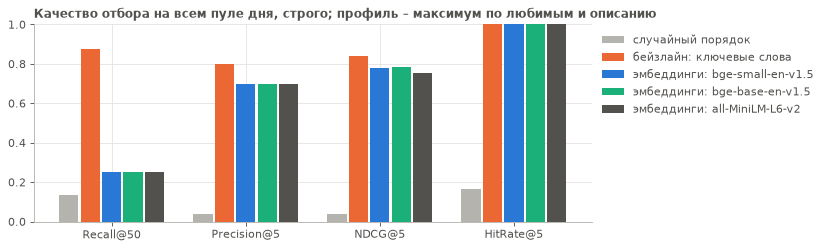

In [18]:
if ready:
    fig, ax = plt.subplots(figsize=(9, 3.2))
    metrics = ["Recall@50", "Precision@5", "NDCG@5", "HitRate@5"]
    width = 0.8 / len(results)
    palette = [GRAY, ORANGE, BLUE, AQUA, INK]
    for i, (name, row) in enumerate(results.iterrows()):
        pos = np.arange(len(metrics)) + i * width - 0.4 + width / 2
        ax.bar(pos, row[metrics], width=width * 0.9, color=palette[i % len(palette)], label=name)
    ax.set_xticks(np.arange(len(metrics)), metrics)
    ax.set_ylim(0, 1)
    ax.set_title(
        "Качество отбора на всем пуле дня, строго; профиль – максимум по любимым и описанию"
    )
    ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
    show(fig, "06_selection_metrics")

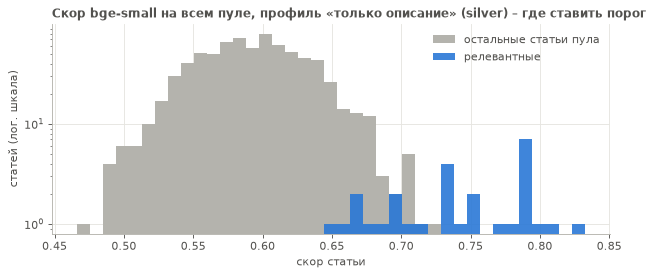

 перцентиль дня  статей в день  из них размечено  точность  полнота по выборке
           0.90           40.5              0.59      0.35                1.00
           0.95           20.5              0.83      0.59                0.83
           0.98           10.5              1.00      0.95                0.50
           0.99            4.5              1.00      1.00                0.00


In [19]:
if ready:
    for i, (ann, frame) in enumerate(scored.items()):
        best = variants["строго"].loc[ann]["NDCG@5"].idxmax()
        col = f"prof:{best}"
        rel = frame["label"] == 1
        rel_sample = rel & frame["in_sample"]
        fig, ax = plt.subplots()
        bins = np.linspace(frame[col].min(), frame[col].max(), 40)
        ax.hist(frame.loc[~rel, col], bins=bins, color=GRAY, label="остальные статьи пула")
        ax.hist(frame.loc[rel, col], bins=bins, color=BLUE, alpha=0.9, label="релевантные")
        ax.set_yscale("log")
        ax.set_title(f"Скор bge-small на всем пуле, профиль «{best}» ({ann}) – где ставить порог")
        ax.set_xlabel("скор статьи")
        ax.set_ylabel("статей (лог. шкала)")
        ax.legend()
        show(fig, "07_score_threshold" if i == 0 else f"07_score_threshold_{ann}")
        percentile = frame.groupby("day")[col].rank(pct=True)
        labeled = frame["id"].isin(labels.loc[labels["annotator"] == ann, "id"])
        rows = []
        for q in (0.9, 0.95, 0.975, 0.99):
            above = percentile > q
            rows.append(
                {
                    "перцентиль дня": q,
                    "статей в день": above.sum() / frame["day"].nunique(),
                    "из них размечено": labeled[above].mean(),
                    "точность": rel[above].mean(),
                    "полнота по выборке": rel_sample[above].sum() / rel_sample.sum(),
                }
            )
        print(pd.DataFrame(rows).round(2).to_string(index=False))

**Вывод.**
- На всем пуле дня Precision@5 и NDCG@5 у всех методов выше, чем на выборке: релевантных статей
  в пуле в несколько раз больше (29 против 6), и найти пять подходящих легче. Recall@50,
  наоборот, ниже: top-50 из ~400 статей – это 12% пула, а не половина выборки; у случайного
  порядка Recall@50 = 0,14 вместо 0,50. Выборка по одной основной категории завышала полноту
  (у профиля «максимум» 1,00 вместо 0,25) и занижала точность top-5 (у «только описание» 0,50
  вместо 1,00), поэтому дальше считаем метрики на всем пуле с пулингом.
- Ключевые слова на этом профиле – сильный бейзлайн: Recall@50 = 0,88, Precision@5 = 0,80,
  NDCG@5 = 0,84. Ложные срабатывания остаются: «рекомендации» по удобрениям или по настройке
  ввода-вывода HPC, `ranking` в статьях о квантовании LLM и предсказании связей в графах.
  Совпадение хотя бы с одним словом есть у 14% пула, и сортировать их, кроме как по числу
  совпадений, нечем.
- Профиль «максимум по любимым статьям» теряет большую часть релевантных уже на шаге кандидатов:
  Recall@50 = 0,25, релевантные статьи выборки на 7–158 местах из ~400. Одна любимая статья
  тянет за собой все похожее на нее (статья о внутренностях RAG-модели – работы по
  интерпретируемости).
- Профиль «только описание интересов» и гибрид «ключевые слова, затем косинус» дают
  Recall@50 = 1,00 и Precision@5 = 1,00, средний вектор – 0,62 и 1,00. В мягком варианте
  Recall@50 ниже (0,70 и 0,68), порядок тот же. Top-5 у лучших вариантов упирается в потолок,
  различает их только Recall@50. Потолок – следствие «серебряной» разметки: описание и
  критерий писал тот же разметчик.
- Три модели при одинаковом профиле на пуле почти равны (NDCG@5 0,75–0,78), на выборке MiniLM
  заметно хуже. bge-base в 2,5 раза медленнее bge-small, поэтому для MVP берем bge-small.
- Порог по перцентилю дня (профиль «только описание»): выше 97,5-го (~10 статей в день)
  точность 0,95 при полноте по выборке 0,50; выше 95-го (~20 статей) полнота 0,83, точность не
  ниже 0,59 (размечено 83% статей выше порога); выше 90-го полнота 1,00. Абсолютные значения
  скора зависят от профиля, поэтому в MVP порог задаем перцентилем дня с нижней границей по
  косинусу, а не одним числом на всех.
- Ограничения: «серебряная» разметка, 2 дня, полнота оценена по 6 статьям выборки. Это
  проверка конвейера и направления, а не окончательный выбор; выбор фиксируем на ручной
  разметке и проверяем на закрытых днях.

## 6. Итоги для дизайн-документа

**Вывод.**

| Вопрос | Ответ EDA | Что меняем в дизайне |
| --- | --- | --- |
| Сколько кандидатов в день | Медиана пакета анонса ~490, понедельник ~840, пики до ~1 000; поток растет на ~35% в год | Отбор и бюджет считаем на пул до 1 000 статей; пересмотр раз в полгода |
| Что в пуле | 41% – cross-list из других категорий | Gold-набор пилотных пользователей – из всего пула |
| Качество метаданных | Чистые: нет пропусков и дубликатов; 12% – версии 2+, LaTeX в 15–18% аннотаций | Дедупликация по id без версии; упрощение формул в карточках |
| Полный текст | HTML 94%, LaTeX 97%, PDF 100%; основной текст ~10,5 тыс. токенов | Каскад HTML → LaTeX → PDF; обрезка литературы и приложений |
| Стоимость | ~45 ₽ на пользователя в месяц против порога 150 ₽ | Оценка из 1.2 снижена, запас на повторные генерации |
| Отбор | На всем пуле дня («серебряная» разметка с пулингом) профиль «описание интересов» не теряет релевантных на шаге кандидатов (Recall@50 1,00 против 0,88 у ключевых слов), «максимум по любимым статьям» теряет три четверти (0,25); выборка по основной категории завышала полноту и занижала точность top-5 | В MVP профиль строится от описания интересов, любимые статьи – дополнительным сигналом; порог – перцентиль дня; гибрид с ключевыми словами – кандидат; метрики считаем на всем пуле с пулингом |
| Чего не хватает | Разметки реальных пользователей: в случайной выборке 6 положительных меток, полнота по ним шумная | Разметка автора и 3–5 пилотных пользователей до пилота |